# Tennis Match History Project
**Team:** Phouvadeth Vathana, Joseph Bronyah, Dhrumil Patel

This notebook runs the code in `tennis_project.py` and `tennis_analyses.py`.
Keep both files in the same folder as this notebook.

**Questions:** performance after ranking upsets; repeat-opponent history;
performance against left-handed opponents.

The output is observational evidence, not proof of psychological recovery or causation.
Read `README.md` for the scope, match-order approximation, and model definitions.

## 1. Install dependencies
Run `python -m pip install -r requirements.txt` in your terminal before opening the notebook.
The cell below is an optional alternative for an existing notebook environment.

In [1]:
# Uncomment if needed, then restart the kernel after installation.
# %pip install -r requirements.txt

In [2]:
from pathlib import Path
import json
import logging
import pandas as pd
from IPython.display import display, Image
from tennis_project import Config, run_project

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
assert Path("tennis_analyses.py").exists(), "Open this notebook from the extracted project folder."

## 2. Choose the full study or the offline demonstration

`RUN_FULL_STUDY = True` downloads the pinned annual ATP files. The default main
period is 2000–2024, with 1990–1999 for earlier history. Change the configuration
before running to adjust the dates or upset definition.

`False` runs **31 real source rows from Brisbane 2024**. This checks code only;
it is not enough data to answer the research questions. The models will be skipped.

Default ranking upset: a top-50 player loses to someone at least 30 ranking
places lower. This is a chosen ranking-based definition, not betting odds.

In [3]:
RUN_FULL_STUDY = True

config = Config(
    history_start=1990,
    analysis_start=2000,
    end_year=2024,
    test_start=2020,
    upset_max_rank=50,
    upset_rank_gap=30,
    min_hand_matches=10,
    bootstrap_samples=500,
    output_dir="outputs",
)
input_files = None
if not RUN_FULL_STUDY:
    config.history_start = config.analysis_start = config.end_year = 2024
    config.output_dir = "demo_outputs"
    input_files = [Path("tests/fixtures/brisbane_2024_excerpt.csv")]
    print("DEMONSTRATION ONLY: not the full research dataset.")

## 3. Download, validate, build features, and analyze
The program caches original files and records hashes. Failed downloads are not
silently skipped. A rerun replaces known generated outputs in the selected
output directory; use a new directory to preserve an earlier configuration.

In [4]:
summary = run_project(config, input_files=input_files)
output = Path(config.output_dir)
print("Raw match rows:", summary["raw_match_rows"])
print("Eligible analysis matches:", summary["eligible_analysis_matches"])
for question in ["q1", "q2", "q3"]:
    print(question.upper(), summary[question]["status"])

INFO: Loaded 112056 raw match rows from 35 file(s).
INFO: Saved results in /Users/dhrumil/Fall 2026/FDA/tennis_final_project/outputs


Raw match rows: 112056
Eligible analysis matches: 63784
Q1 Q1 descriptive tables and exploratory adjusted recovery-rate regression fitted.
Q2 Chronological Q2 comparison fitted: baseline, +meeting count, +head-to-head results.
Q3 Q3 descriptive tables and within-player adjusted linear probability model fitted.


## 4. Check data quality before interpreting results
Counts refer to physical matches. The feature table has two player views per
match, so its row count is not a count of independent matches.

The program screens incomplete results and ambiguity, but does not independently
verify exact match dates or every tennis score.

In [5]:
display(pd.read_csv(output / "coverage_by_year.csv"))
display(pd.read_csv(output / "missing_values.csv"))
display(pd.read_csv(output / "player_row_quality.csv"))
print("Exclusion flags (overlapping):")
print(json.dumps(summary["exclusion_flag_counts_nonexclusive"], indent=2))

,season,source_matches,eligible_matches,unknown_winner_hands,unknown_loser_hands
0,1990,3743,3301,35,88
1,1991,3727,3286,38,83
2,1992,3730,3322,36,60
3,1993,3890,3477,22,54
4,1994,3938,3516,21,54
5,1995,3800,3356,23,46
6,1996,3836,3340,13,56
7,1997,3561,3103,14,41
8,1998,3591,3129,15,49
9,1999,3334,2887,15,51


,field,missing_count,missing_percent
0,tourney_id,0,0.000000
1,tourney_name,0,0.000000
2,tourney_date,0,0.000000
3,tourney_level,0,0.000000
4,round,0,0.000000
5,match_num,0,0.000000
6,surface,0,0.000000
7,best_of,0,0.000000
8,score,0,0.000000
9,winner_id,0,0.000000


,flag,count
0,unknown_player_hand_rows,1878
1,missing_player_rank_rows,4026
2,invalid_or_missing_service_stat_rows,28049


Exclusion flags (overlapping):
{
  "invalid_player_ids": 0,
  "conflicting_match_key": 0,
  "outside_individual_AMG_scope": 11107,
  "unfinished_or_unrecognized_score": 3505,
  "ambiguous_order": 12385,
  "outside_history_window": 0,
  "missing_match_key": 0
}


In [6]:
features = pd.read_csv(output / "player_match_features.csv.gz")
columns = ["match_id", "player_name", "opponent_name", "won", "eligible",
           "player_age", "player_hand", "opponent_hand", "prior_matches",
           "recent_win_rate", "prior_h2h_meetings", "prior_h2h_wins"]
display(features[columns].head(12))

,match_id,player_name,opponent_name,won,eligible,player_age,player_hand,opponent_hand,prior_matches,recent_win_rate,prior_h2h_meetings,prior_h2h_wins
0,2000-339:1,Thomas Enqvist,Arnaud Clement,1,True,25.7,R,R,430.0,0.9,1.0,0.0
1,2000-339:1,Arnaud Clement,Thomas Enqvist,0,True,22.0,R,R,102.0,0.3,1.0,1.0
2,2000-339:10,Stephane Huet,Dejan Petrovic,0,True,28.6,L,R,25.0,0.3,0.0,0.0
3,2000-339:10,Dejan Petrovic,Stephane Huet,1,True,21.7,R,L,0.0,NaN,0.0,0.0
4,2000-339:11,Christian Vinck,Paul Goldstein,1,True,24.3,L,R,28.0,0.2,0.0,0.0
5,2000-339:11,Paul Goldstein,Christian Vinck,0,True,23.3,R,L,34.0,0.5,0.0,0.0
6,2000-339:12,Jason Stoltenberg,Dominik Hrbaty,1,True,29.7,R,R,424.0,0.3,0.0,0.0
7,2000-339:12,Dominik Hrbaty,Jason Stoltenberg,0,True,21.9,R,R,162.0,0.3,0.0,0.0
8,2000-339:13,Nicolas Escude,Paul Baccanello,1,True,23.7,R,R,91.0,0.6,0.0,0.0
9,2000-339:13,Paul Baccanello,Nicolas Escude,0,True,20.5,R,R,0.0,NaN,0.0,0.0


## 5. Question 1: performance after ranking upsets
Age and experience are separate variables. Experience counts earlier eligible
recorded matches, not the entire professional career.

A missing follow-up window is not zero wins. The next-three-match rate is
calculated only when all three next recorded matches are eligible. We do not
skip a retirement or an ambiguous event to find later favorable observations.

The following summaries are **unadjusted**. The optional adjusted rate model
uses a common rank-eligible population and accounts for observed strength,
recent form, age, experience, surfaces, format, and season. Its results are
exploratory associations, with focal-player-clustered uncertainty.

In [7]:
display(pd.read_csv(output / "q1_summary_age.csv"))
display(pd.read_csv(output / "q1_summary_experience.csv"))
display(pd.read_csv(output / "q1_threshold_sensitivity.csv"))
print(json.dumps(summary["q1"], indent=2))

,loss_type,age_group,index_losses,unique_players,usable_next_matches,next_match_win_rate,complete_three_match_windows,next_three_win_rate,mean_age,mean_prior_matches
0,other_ranked_loss,under_23,11104,863,9505,0.506575,8015,0.495862,21.092012,50.399496
1,other_ranked_loss,23_to_29,33424,1237,29048,0.507711,24582,0.487403,26.392490,161.769716
2,other_ranked_loss,30_plus,11502,443,10071,0.485354,8444,0.465103,32.378821,400.705269
3,ranking_upset,under_23,1223,122,1070,0.661682,936,0.632123,21.470155,124.970564
4,ranking_upset,23_to_29,4794,285,4225,0.621538,3715,0.591386,26.285774,282.439925
5,ranking_upset,30_plus,1519,127,1400,0.582143,1234,0.572123,32.317775,538.860434
6,unknown_rank,under_23,69,61,40,0.300000,30,0.355556,19.026087,4.478261
7,unknown_rank,23_to_29,101,66,73,0.369863,59,0.389831,27.080198,161.059406
8,unknown_rank,30_plus,48,44,26,0.346154,22,0.333333,33.029167,268.770833


,loss_type,experience_group,index_losses,unique_players,usable_next_matches,next_match_win_rate,complete_three_match_windows,next_three_win_rate,mean_age,mean_prior_matches
0,other_ranked_loss,under_100,25704,1437,21824,0.438096,18082,0.427423,24.382143,38.290033
1,other_ranked_loss,100_to_299,17193,367,15215,0.537430,13064,0.513498,26.899098,182.461700
2,other_ranked_loss,300_plus,13133,197,11585,0.579456,9895,0.550379,30.425242,491.454199
3,ranking_upset,under_100,993,205,887,0.510710,789,0.505703,23.074119,67.934542
4,ranking_upset,100_to_299,3268,237,2889,0.626514,2540,0.587402,25.171695,196.799266
5,ranking_upset,300_plus,3275,156,2919,0.646112,2556,0.627413,29.370687,493.064427
6,unknown_rank,under_100,135,111,67,0.268657,47,0.319149,23.495556,9.066667
7,unknown_rank,100_to_299,30,26,23,0.391304,21,0.317460,28.576667,191.100000
8,unknown_rank,300_plus,53,24,49,0.428571,43,0.449612,30.266038,424.905660


,rank_gap_threshold,age_group,index_losses,complete_windows,next_three_win_rate
0,20,under_23,1559,1194,0.634283
1,20,23_to_29,6089,4709,0.595597
2,20,30_plus,1887,1523,0.565769
3,30,under_23,1223,936,0.632123
4,30,23_to_29,4794,3715,0.591386
5,30,30_plus,1519,1234,0.572123
6,50,under_23,720,558,0.632019
7,50,23_to_29,2898,2264,0.588045
8,50,30_plus,925,740,0.562613


{
  "index_losses": 63784,
  "ranking_upsets": 7536,
  "complete_three_match_followups": 47037,
  "status": "Q1 descriptive tables and exploratory adjusted recovery-rate regression fitted.",
  "adjusted_model_eligible_events": 18471,
  "model_events": 18471,
  "model_players": 341,
  "model_formula": "next3_win_rate ~ ranking_upset * (age_centered + log_experience) + recent_win_rate + log_player_rank + followup_mean_log_rank_advantage + followup_clay_share + followup_grass_share + followup_carpet_share + followup_best_of_5_share + C(surface) + C(season)",
  "uncertainty": "Player-clustered standard errors; not full opponent/network dependence."
}


In [8]:
q1_coefficients = output / "q1_adjusted_coefficients.csv"
if q1_coefficients.exists():
    display(pd.read_csv(q1_coefficients))
else:
    print("Q1 adjustment was not fitted. See the status above; no result has been invented.")

,term,coefficient,standard_error,ci95_lower,ci95_upper
0,Intercept,0.255358,0.055933,0.145731,0.364985
1,C(surface)[T.Clay],-0.008381,0.014485,-0.036771,0.020010
2,C(surface)[T.Grass],0.038273,0.015609,0.007681,0.068865
3,C(surface)[T.Hard],0.014785,0.013177,-0.011042,0.040612
4,C(season)[T.2001],0.007519,0.021027,-0.033693,0.048732
5,C(season)[T.2002],0.018603,0.019497,-0.019610,0.056816
6,C(season)[T.2003],0.024482,0.020590,-0.015874,0.064838
7,C(season)[T.2004],0.042659,0.020104,0.003256,0.082062
8,C(season)[T.2005],0.013853,0.017373,-0.020197,0.047902
9,C(season)[T.2006],0.027800,0.018935,-0.009312,0.064912


## 6. Question 2: do previous meetings improve predictions?
Compare the baseline, baseline plus meeting count, and baseline plus head-to-head
results. They use the same earlier-season training set and later-season test set.

**Lower Brier score and log loss are better.** In the paired Brier comparison,
a positive improvement means the full head-to-head model had lower error than
the baseline. An interval spanning zero does not provide a clear direction.

Earlier test outcomes can update later test histories, but the prediction
models remain frozen. No current-match statistics or future outcomes are predictors.
Opponent-pair bootstrap intervals do not capture all shared-player dependence.

In [9]:
metrics_file = output / "q2_model_metrics.csv"
if metrics_file.exists():
    metrics = pd.read_csv(metrics_file)
    display(metrics.loc[metrics["meeting_group"].eq("all")])
    display(metrics.loc[~metrics["meeting_group"].eq("all")])
else:
    print("Insufficient data for the chronological model comparison.")
print(json.dumps(summary["q2"], indent=2))

,model,meeting_group,test_matches,brier_score,log_loss,accuracy
0,baseline,all,11340,0.216957,0.622392,0.646561
5,plus_meeting_count,all,11340,0.216979,0.622421,0.647531
10,plus_h2h_results,all,11340,0.216371,0.620970,0.648148


,model,meeting_group,test_matches,brier_score,log_loss,accuracy
1,baseline,0,6460,0.218058,0.624868,0.644737
2,baseline,1,2345,0.216520,0.620514,0.640512
3,baseline,2_to_4,2027,0.215390,0.619963,0.653182
4,baseline,5_plus,508,0.211233,0.609274,0.671260
6,plus_meeting_count,0,6460,0.218059,0.624826,0.645666
7,plus_meeting_count,1,2345,0.216478,0.620425,0.642217
8,plus_meeting_count,2_to_4,2027,0.215443,0.620110,0.654662
9,plus_meeting_count,5_plus,508,0.211680,0.610274,0.667323
11,plus_h2h_results,0,6460,0.217827,0.624247,0.644737
12,plus_h2h_results,1,2345,0.215775,0.618986,0.646482


{
  "status": "Chronological Q2 comparison fitted: baseline, +meeting count, +head-to-head results.",
  "training_matches": 52444,
  "test_matches": 11340,
  "test_start": 2020,
  "orientation": "Player A has the smaller numeric player ID, independent of match outcome.",
  "paired_brier_comparison": {
    "status": "Computed",
    "mean_brier_improvement": 0.0005861619938616038,
    "ci95_lower": 9.464228086397671e-05,
    "ci95_upper": 0.0010191004962474218,
    "pair_clusters": 7824,
    "resamples": 500,
    "limitation": "Pair-cluster resampling does not capture every shared-player dependence across different pairs."
  },
  "convergence_warnings": [],
  "primary_metric": "Brier score (lower is better). Both models are evaluated on exactly the same held-out matches.",
  "test_history_policy": "Earlier held-out results can update later held-out pre-match histories; model parameters stay frozen."
}


## 7. Question 3: left-handed versus right-handed opponents
The paired table contains the **same player's** L-minus-R differences. Raw
service-point rates and win-rate differences are unadjusted and include counts.
A positive raw difference means better recorded performance against left-handers.

The optional within-player model adjusts match-result comparisons. Its
`opponent_left` coefficient describes right-handed focal players; add the
interaction for left-handed focal players. A coefficient of 0.02 means about
two percentage points, not 2% relative growth. This is not a causal estimate.

In [10]:
by_hand = pd.read_csv(output / "q3_by_player_and_hand.csv")
paired = pd.read_csv(output / "q3_paired_player_comparison.csv")
display(by_hand.head(12))
display(paired.head(12))
coeff_file = output / "q3_adjusted_coefficients.csv"
if coeff_file.exists():
    coefficients = pd.read_csv(coeff_file)
    display(coefficients.loc[coefficients["term"].str.contains("opponent_left")])
else:
    print("Insufficient data for the within-player adjusted model.")
print(json.dumps(summary["q3"], indent=2))

,player_id,opponent_hand,matches,wins,win_rate,service_matches,service_points_won,service_points_observed,service_win_rate
0,100644,L,76,63,0.828947,76,3949.0,5842.0,0.675967
1,100644,R,501,344,0.686627,501,26957.0,40755.0,0.661440
2,101086,L,3,0,0.000000,3,129.0,240.0,0.537500
3,101086,R,22,6,0.272727,22,1044.0,1771.0,0.589497
4,101150,L,14,5,0.357143,14,603.0,1016.0,0.593504
5,101150,R,62,26,0.419355,62,3114.0,5097.0,0.610948
6,101167,L,1,0,0.000000,1,23.0,51.0,0.450980
7,101185,L,2,0,0.000000,2,115.0,194.0,0.592784
8,101185,R,7,3,0.428571,7,317.0,522.0,0.607280
9,101191,R,2,1,0.500000,2,73.0,123.0,0.593496


,player_id,matches_L,matches_R,win_rate_L,win_rate_R,service_win_rate_L,service_win_rate_R,win_rate_difference_L_minus_R,service_rate_difference_L_minus_R,player_name
0,100644,76.0,501.0,0.828947,0.686627,0.675967,0.661440,0.142321,0.014527,Alexander Zverev
1,101150,14.0,62.0,0.357143,0.419355,0.593504,0.610948,-0.062212,-0.017444,Gianluca Pozzi
2,101532,18.0,126.0,0.444444,0.420635,0.621005,0.608484,0.023810,0.012520,Francisco Clavet
3,101611,12.0,100.0,0.666667,0.470000,0.673257,0.628798,0.196667,0.044459,Cedric Pioline
4,101647,11.0,62.0,0.454545,0.483871,0.600457,0.622813,-0.029326,-0.022356,Byron Black
5,101723,11.0,46.0,0.727273,0.500000,0.663311,0.640633,0.227273,0.022678,Magnus Larsson
6,101736,43.0,279.0,0.674419,0.792115,0.666118,0.671940,-0.117696,-0.005822,Andre Agassi
7,101774,15.0,122.0,0.800000,0.516393,0.693841,0.653676,0.283607,0.040165,Todd Martin
8,101792,11.0,46.0,0.545455,0.326087,0.625663,0.574646,0.219368,0.051016,Slava Dosedel
9,101820,15.0,117.0,0.600000,0.435897,0.652915,0.647143,0.164103,0.005772,Marc Rosset


,term,coefficient,standard_error,ci95_lower,ci95_upper
0,opponent_left,0.011106,0.004235,0.002806,0.019407
1,opponent_left_x_player_left,-0.001172,NaN,NaN,NaN


{
  "status": "Q3 descriptive tables and within-player adjusted linear probability model fitted.",
  "player_match_rows": 127438,
  "unique_matches": 63719,
  "players_meeting_raw_comparison_minimum": 427,
  "adjusted_player_match_rows": 112503,
  "adjusted_unique_matches": 61412,
  "adjusted_players": 420,
  "covariance": "Two-way clustered by focal player and physical match; other shared-opponent dependence may remain.",
  "ci_note": "Large-sample normal intervals; exploratory, not causal.",
  "negative_variance_terms": 1,
  "interpretation": "opponent_left is the adjusted L-minus-R contrast for right-handed focal players; add the interaction for left-handed focal players. Coefficients are probability units."
}


## 8. Exploratory charts
The recovery and paired handedness charts are unadjusted descriptions. Read
the opportunity counts and adjusted outputs before interpreting them.

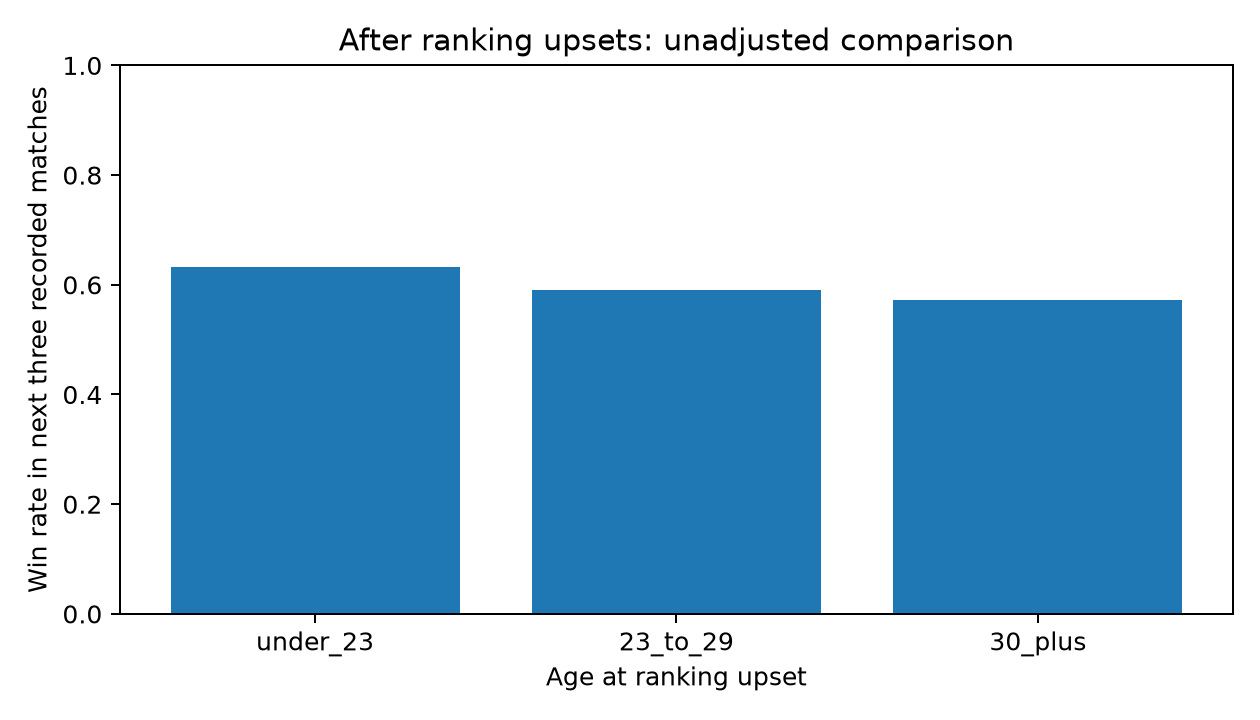

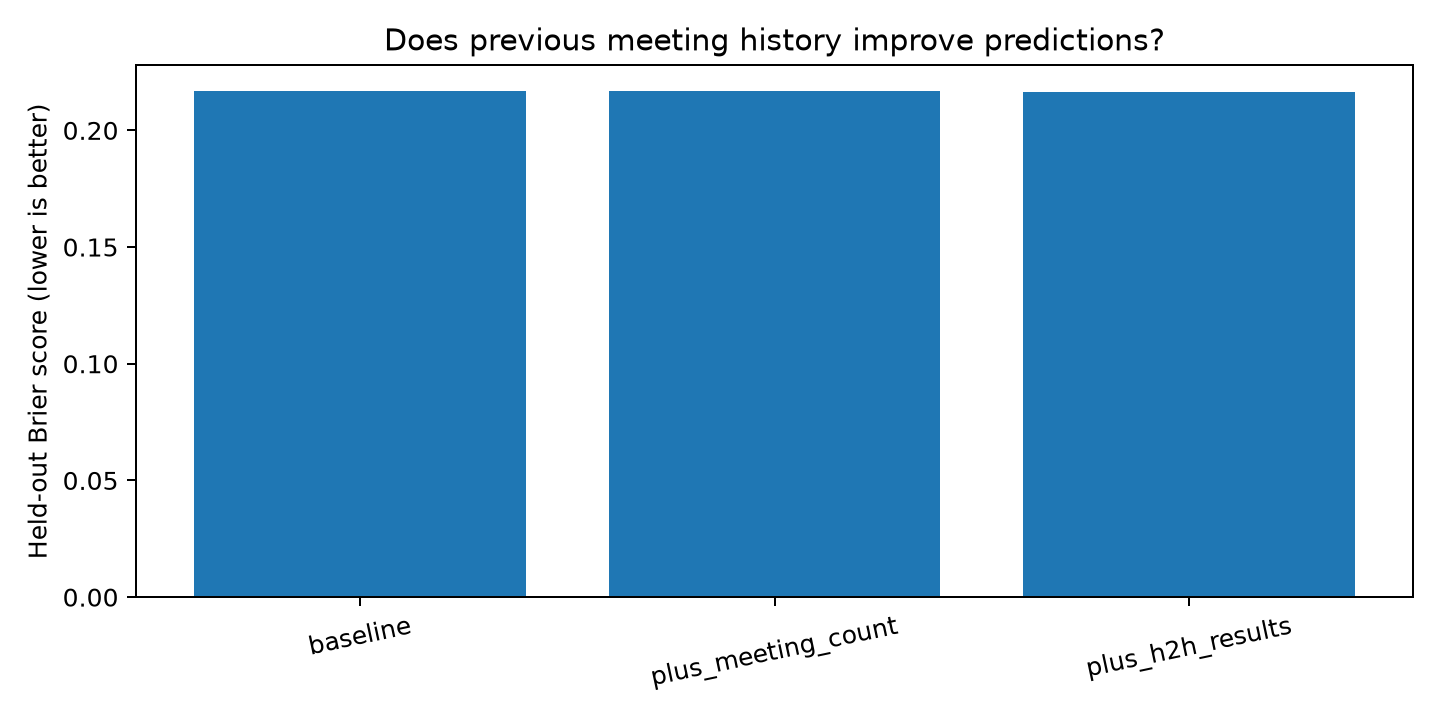

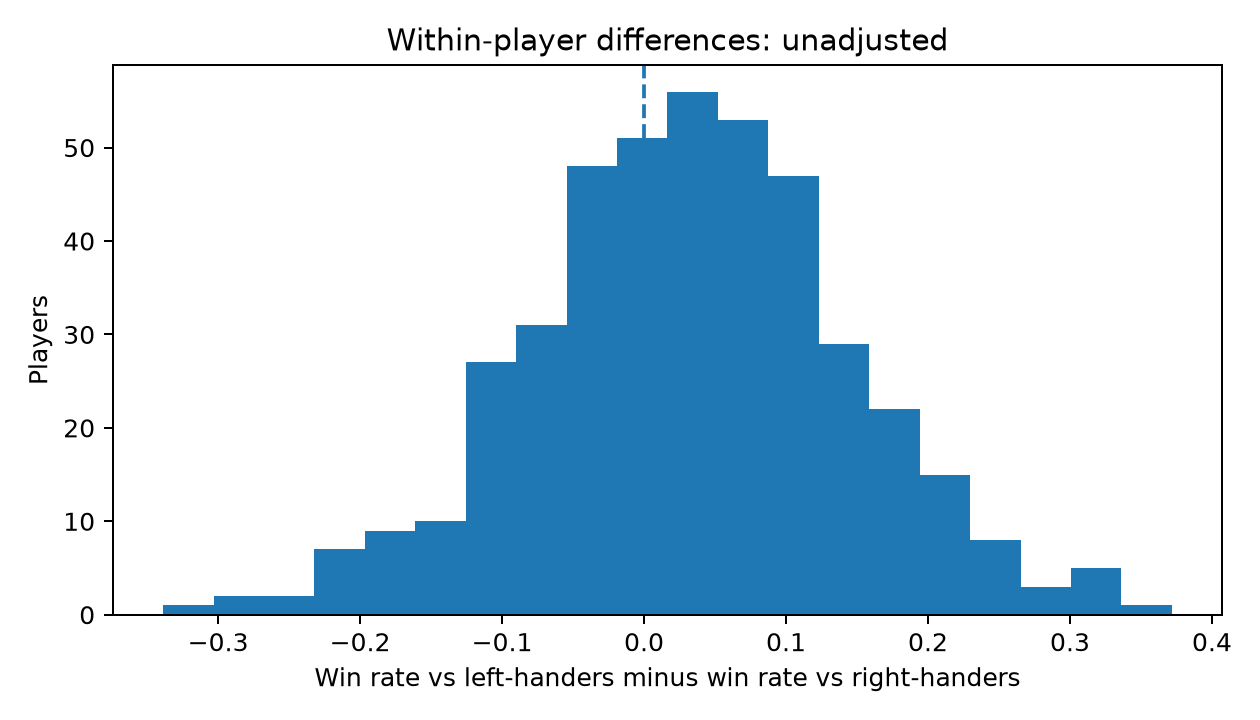

In [11]:
chart_files = sorted((output / "charts").glob("*.png"))
if not chart_files:
    print("No charts available for this sample.")
for path in chart_files:
    display(Image(filename=str(path)))

## 9. Before writing the report
Report actual source and eligible match counts, missing information, exclusions,
and the chosen upset definition. Keep age and experience separate. Describe
match order as inferred from tournament week and knockout round, not verified
match-day dates. Label early-history counts as observed history rather than
complete careers. Report follow-up censoring and uncertainty.

`SOURCES.md` and `DATA_LICENSE.txt` contain attribution. `run_summary.json`
records configuration, model status, versions, and input hashes.

The bundled real sample and synthetic test fixtures verify implementation;
they do not establish the answers to your research questions.

In [12]:
# Optional: run the automated implementation checks.
# !python -m pytest -q